# Generate source-level connectomes from tractograms

In this tutorial, we show how to generate a source-level connectome from an individual subject's tractogram. The connectome is used to define its connectome spectrum transform, which is an essential part of the CSET method. <br>

Tractography is a 3D modeling technique that visualizes nerve tracts based on data from diffusion MRI. The output is typically displayed as two- or three-dimensional images known as tractograms, which illustrate the physical connections between brain regions. These connections can be represented as a graph, called a **structural connectome**, where nodes correspond to brain regions and edges represent structural links. In our context, brain regions are modeled as dipoles in the source model. To determine which dipoles are connected, we apply a nearest-neighbor algorithm to the endpoints of the nerve tracts. Each tract thereby identifies a connection between specific dipoles. <br>

In more detail, the following steps are applied:
1. **Filter out non-credible tracts** to eliminate spurious or anatomically implausible connections.
2. **Associate tract endpoints with dipoles** using a nearest-neighbor algorithm.
3. **Smooth the results** to generate a high-resolution connectome.
4. **Add local neighbor connections** to account for interactions within gray matter.
5. **Assign informative weights** to the connections based on tract-specific properties.

(J'aimerai bien un petit shéma la)

## 🧪 - Experiment setup
- `src`: Source Space
- `tractogram`: Tractogram
- `ctx`: Cortical Mask
- `t12diff`: T1 subject space to Diffusion space transform
- `ras2tkras`: T1 subject space to FreeSurfer space transform

In [1]:
# imports
import mindmap as mm
import numpy as np
import nibabel as nib
import pyvista as pv

# data manager
dm = mm.io.TutoManager("../../config.yml")
sub = "simf10"

# data
src = dm.load(sub, "fwd", desc="sim")["src"]
tracto = dm.load(sub, "tractogram")
t12diff = dm.load(sub, "t12diff")
ctx = dm.load(sub, "ctx", space="fs", segmentation="multiconn2022", scale="4")
ras2tkras = dm.load(sub, "ras2tkras")

## 🧬 - Data Processing

Compute connectivity matrix from tractogram.

In [2]:
# prune tractogram (delete none-gray matter endings)
pruned_tracto, deleted_tracto = mm.anatomy.tractogram.prune_tracts(tracto, ctx, t12diff, return_pruned=True)

# build (length) connectivity matrix
con_tracto = mm.analysis.connectivity.connectome_from_tracts(pruned_tracto, src, t12diff, ras2tkras, lengths=True)

Add geometry connections.

In [3]:
con_geom = mm.analysis.connectivity.connectome_from_geometry(
    src,
    maximum_dist = 15,
    maximum_neigh = 3,
    weights = True,
)

# fuse connectomes
con = con_tracto.copy()
geom_idx = np.argwhere(con_geom > 0)
con[geom_idx[:,0], geom_idx[:,1]] = con_geom[geom_idx[:,0], geom_idx[:,1]]

## 📊 - Visualization
Source Space - Diffusion Space alignment

In [4]:
# Gray matter (voxel -> RAS)
gm_points = np.argwhere(ctx.get_fdata()>0)
gm_points = nib.affines.apply_affine(ctx.affine, gm_points)

# Dipoles (tkras -> voxel -> RAS)
dipoles = mm.anatomy.source_space.get_dipole_positions(src)*1000    # converted to [mm]
dipoles = nib.affines.apply_affine(np.linalg.inv(ras2tkras), dipoles)

# Diffusion tracts (diffusion -> voxel -> RAS)
dwi_points = np.vstack(mm.anatomy.tractogram.tract_endpoints(tracto))
#affine = data["ctx"].affine @ np.linalg.inv(data["t12diff"]) @ np.linalg.inv(data["tracto"].affine)        # what I excpected but it doesn't work, check with Yasser
#dwi_points = nib.affines.apply_affine(affine, dwi_points)
dwi_points = mm.anatomy.align_diffusion2subject(dwi_points, t12diff)

p = pv.Plotter()
p.add_mesh(gm_points, color="white", opacity=0.05, render_points_as_spheres=True, point_size=5, label="Gray matter")
p.add_mesh(dipoles, color="black", render_points_as_spheres=True, point_size=5, label="dipoles")
p.add_mesh(dwi_points, color="green", render_points_as_spheres=True, point_size=3, label="dwi")
p.show()

Widget(value='<iframe src="http://localhost:40111/index.html?ui=P_0x70332c07ae10_0&reconnect=auto" class="pyvi…

Pruning results.

In [5]:
# extract endpoints
pruned_points  = np.vstack(mm.anatomy.tractogram.tract_endpoints(pruned_tracto))
deleted_points = np.vstack(mm.anatomy.tractogram.tract_endpoints(deleted_tracto))

percent = len(deleted_points)/(len(deleted_points)+len(pruned_points))*100
print(f"Number of tracts removed: {percent:.1f} %")

# align points
pruned_points = mm.anatomy.align_diffusion2subject(pruned_points, t12diff)
deleted_points = mm.anatomy.align_diffusion2subject(deleted_points, t12diff)

# plot
p = pv.Plotter()
p.add_mesh(gm_points, color="white", opacity=0.05, render_points_as_spheres=True, point_size=5, label="Gray matter")
p.add_mesh(pruned_points, color="green", render_points_as_spheres=True, point_size=3, label="remaining streamline endpoints")
p.add_mesh(deleted_points, color="red", render_points_as_spheres=True, point_size=3, label="deleted streamline endpoints")
p.show()

Number of tracts removed: 26.3 %


Widget(value='<iframe src="http://localhost:40111/index.html?ui=P_0x70332c049890_1&reconnect=auto" class="pyvi…

Tractogram only connectome.

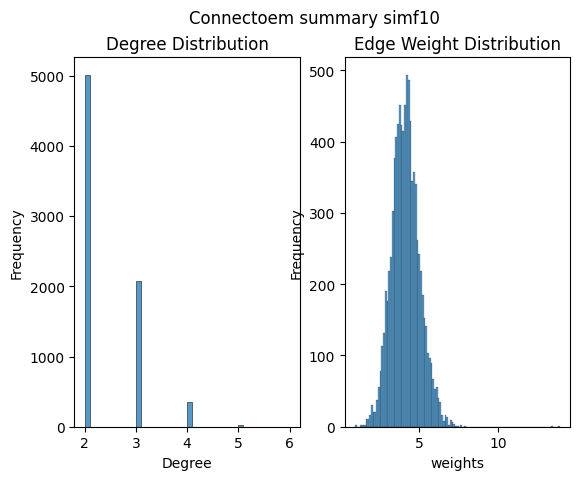

In [ ]:
mm.viz.plot_con_summary(con_tracto, title="Connectoem summary simf10")
#mm.head.print_connectome_summary(conn)

In [7]:
# Visualize isolated nodes
isolated_nodes = np.argwhere(np.sum(con_tracto>0, axis=1)==0).squeeze()
targets = np.zeros(mm.anatomy.source_space.get_ndipole(src))
targets[isolated_nodes] = 1

print(f"Number of isolated nodes: {int(targets.sum())}")
mm.viz.plot_brain(src, targets, overlay=ctx, ras2tkras=ras2tkras).show()

Number of isolated nodes: 264


Widget(value='<iframe src="http://localhost:40111/index.html?ui=P_0x70323467c710_2&reconnect=auto" class="pyvi…

Final Connectome.

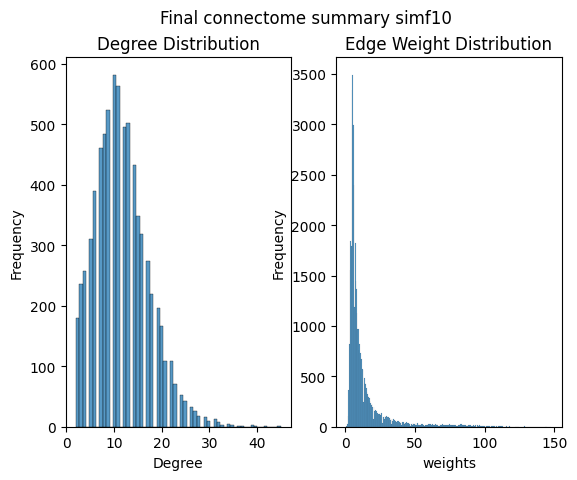

In [8]:
mm.viz.plot_con_summary(con, title="Final connectome summary simf10")

Adjacency matrix.

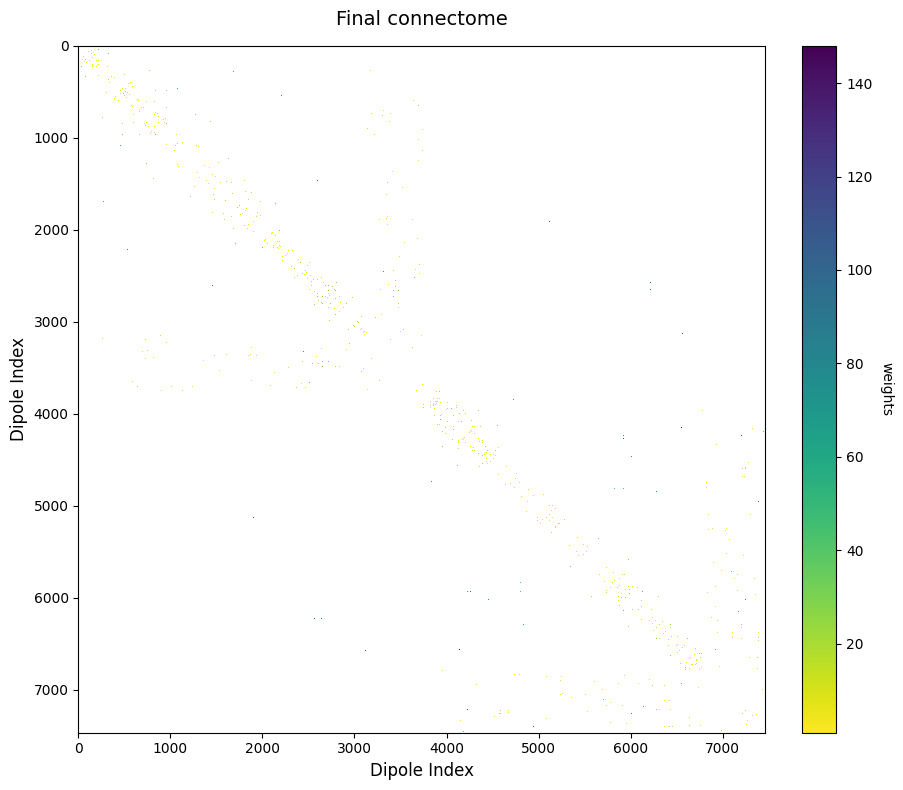

In [11]:
mm.viz.plot_adj_matrix(con, title="Final connectome")

In [14]:
# Visualize isolated nodes
isolated_nodes = np.argwhere(np.sum(con>0, axis=1)==0).squeeze()
targets = np.zeros(mm.anatomy.source_space.get_ndipole(src))
targets[isolated_nodes] = 1

print(f"Number of isolated nodes: {int(targets.sum())}")
mm.viz.plot_brain(src, targets, overlay=ctx, ras2tkras=ras2tkras).show()

Number of isolated nodes: 0


Widget(value='<iframe src="http://localhost:42203/index.html?ui=P_0x76e9cd8856d0_4&reconnect=auto" class="pyvi…